# Light-Sheet smFRET Camera Simulation — Focusing-Depth Scan, 63x/NA 1.46 oil (DESIGN oil)

*Note: Partially vibe-coded with Mistral GLM-3*

*This notebook lives in and writes all outputs to `ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_depthscan/`*

Companion to `LightSheet_ATTO550_NA1.46_63x_oil_depthscan.ipynb`: the same
focusing-depth scan of the detection PSF, but with the **DESIGN immersion oil**
(ni = ni0 = 1.518, index-matched to the objective) instead of the mismatched
high-index oil (ni = 1.58).

**Why this companion:** with the design oil there is no over-correction — the
water-layer spherical aberration acts alone, so the PSF **degrades
monotonically with depth** (no recovery at 25 um). Comparing the two
notebooks isolates the effect of the immersion-oil choice:

| Depth | Mismatched oil (ni = 1.58) | Design oil (ni = 1.518) |
|---|---|---|
| 1 µm | poor (over-correction) | good (little water path) |
| 10 µm | improving | degraded |
| **25 µm** | **optimal (compensated)** | **degraded (~6x worse than at the coverslip)** |
| 50 µm | degraded again | severely degraded |

Together the two scans tell you: shallow imaging -> use the design oil;
imaging at 25 um -> the mismatched oil recovers the PSF ~4x; the design oil
*never* benefits from depth.

**Scan:** detection PSF at sheet depths **pz = 1, 5, 10, 25, 40, 50 µm**
above the coverslip, all results in combined figures with the focusing depth
indicated (identical figures/structure as the mismatched-oil notebook):
1. In-focus lateral PSF profiles at each depth
2. PSF peak and lateral FWHM vs. depth (monotonic deterioration curves)
3. Axial PSF profiles at each depth
4. XZ cross-sections at each depth

**Shared configuration:** ATTO550-DNA in aqueous buffer (ns = 1.333), Zeiss
63x/NA 1.46 oil detection, Mitutoyo sheet lens (NA 0.08), Alvium 1800 U-158
with 2x2 binning. Sections 2-4 retain the standard 25-um camera simulation
with the DESIGN oil, so the scan flows into rendered frames.

In [1]:
%matplotlib inline
import os
import sys
import numpy as np
import tables
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import imageio.v3 as iio
import pybromo as pbm
import psfmodels

# LightSheetPSF lives in the repository base directory (one level up)
sys.path.insert(0, os.path.abspath('..'))
from lightsheet_psf import LightSheetPSF

# All results of this configuration are written into THIS notebook's directory
OUTPUT_DIR = os.path.abspath('.')          # .../ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x
os.chdir(OUTPUT_DIR)
print('Output directory:', OUTPUT_DIR)

print('Numpy version:', np.__version__)
print('PyTables version:', tables.__version__)
print('PyBroMo version:', pbm.__version__)
print('psfmodels version:', psfmodels.__version__)

Output directory: /Users/tomkache/Documents/Arbeit/EAH/Software/python/Lightsheet_smFRET_Simulations/H2MM-FRET-Blinking/ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_mismatch25um
Numpy version: 1.26.4
PyTables version: 3.9.2
PyBroMo version: 0.8.1
psfmodels version: 0.3.3


## 1. Depth-dependent detection PSF: the scan

The detection PSF of the oil objective depends on the sheet depth `pz` through
the Gibson–Lanni model: the deeper the sheet, the more water the rays traverse.
With the DESIGN oil (ni = ni0 = 1.518) there is no compensation term — the
water-layer aberration accumulates monotonically, so the PSF degrades with
depth without any recovery. We compute the detection PSF stack at six depths
and compare them; the figure files are prefixed `designoil_` to distinguish
them from the mismatched-oil scan in the companion notebook.

*Note on the scan grid:* the lateral grid (`dxy = 0.0548 um`, `nx = 91`) is
finer than the rendering grid on purpose — it measures the true PSF FWHM
(~0.2 um, ~4 grid steps) without pixel-size bias.

In [ ]:
# --- Depth scan of the detection PSF (DESIGN oil, water sample) ---
# Detection PSF at sheet depths pz = 1, 5, 10, 25, 40, 50 um.
# For each depth we compute the in-focus plane (z = pz) with psfmodels
# Gibson-Lanni, plus an axial profile, using the SAME optical parameters
# as the rendering PSF in section 3 (design oil ni = 1.518).
import psfmodels as psfm

depths_um = [1.0, 5.0, 10.0, 25.0, 40.0, 50.0]

# optical parameters (identical to section 3)
det_NA, em_wvl = 1.46, 0.58
ns, ni, ni0 = 1.333, 1.518, 1.518     # water sample, DESIGN oil (index-matched)
ng, ng0, tg, tg0 = 1.515, 1.515, 170.0, 170.0

dxy_scan = 0.0548                     # fine lateral grid (1x sensor pixel)
nx_scan = 91                          # +-2.47 um support: plenty for the FWHM
dz_scan = 0.25                        # axial step for the profiles
nz_scan = 49                          # axial extent +-6 um

def in_focus_psf_at_depth(pz):
    """In-focus lateral PSF plane at depth pz (um) via Gibson-Lanni."""
    zv = pz + (np.arange(nz_scan) - nz_scan//2) * dz_scan   # absolute depths
    p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,
                      NA=det_NA, wvl=em_wvl,
                      ns=ns, ni=ni, ni0=ni0, ng=ng, ng0=ng0,
                      tg=tg, tg0=tg0, ti0=150.0,
                      normalize=True, model='vectorial')
    iz = np.argmin(np.abs(zv - pz))    # the in-focus plane
    return zv, p, iz

psf_planes, axial_profiles, zvs = {}, {}, {}
for pz in depths_um:
    zv, p, iz = in_focus_psf_at_depth(pz)
    psf_planes[pz] = p[iz]
    axial_profiles[pz] = p[:, nx_scan//2, nx_scan//2]
    zvs[pz] = zv
    # metrics: sum-normalized peak + lateral FWHM of the central row
    k = p[iz]; kn = k / k.sum()
    row = kn[nx_scan//2]
    idx = np.where(row >= row.max()/2)[0]
    fwhm = (idx[-1] - idx[0] + 1) * dxy_scan
    print(f'pz = {pz:5.1f} um: peak {kn[nx_scan//2, nx_scan//2]*1e3:6.1f}e-3, '
          f'lateral FWHM {fwhm:.3f} um')

### Figure 1: in-focus lateral PSF profiles vs. focusing depth

In [ ]:
# --- Combined plot: in-focus lateral profiles, depth color-coded ---
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = plt.cm.viridis(np.linspace(0.9, 0.1, len(depths_um)))
x_um = (np.arange(nx_scan) - nx_scan//2) * dxy_scan
for c, pz in zip(colors, depths_um):
    k = psf_planes[pz]; kn = k / k.sum()
    row = kn[nx_scan//2]
    ax.plot(x_um, row / row.max(), color=c, lw=2,
            label=f'{pz:.0f} um (peak {kn[nx_scan//2, nx_scan//2]*1e3:.0f}e-3)')
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel('x (um)')
ax.set_ylabel('Normalized intensity')
ax.set_title('In-focus detection PSF vs. focusing depth\n'
             'Zeiss 63x/NA 1.46 oil (DESIGN oil, ni = 1.518), aqueous sample')
ax.legend(title='Sheet depth', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig1_lateral_profiles.png'),
            dpi=150, bbox_inches='tight');

### Figure 2: PSF peak and lateral FWHM vs. focusing depth

The peak (Strehl-like: sum-normalized in-focus peak — higher = tighter PSF)
decreases monotonically with depth (no compensation with the design oil); the
FWHM broadens correspondingly. The vertical line marks 25 um, where the
mismatched-oil companion notebook shows its optimum — the contrast between
the two scans is the argument for the oil choice.

In [ ]:
# --- Deterioration/recovery curves vs. depth ---
peaks, fwhms = [], []
for pz in depths_um:
    k = psf_planes[pz]; kn = k / k.sum()
    peaks.append(kn[nx_scan//2, nx_scan//2])
    row = kn[nx_scan//2]
    idx = np.where(row >= row.max()/2)[0]
    fwhms.append((idx[-1] - idx[0] + 1) * dxy_scan)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot(depths_um, np.array(peaks)*1e3, 'o-', color='C0')
a1.set_xlabel('Sheet depth (um)'); a1.set_ylabel('In-focus peak (sum-normalized, 1e-3)')
a1.set_title('PSF peak vs. focusing depth')
a1.axvline(25, color='gray', ls=':', lw=1, label='depth of the mismatched-oil optimum')
a1.legend()

a2.plot(depths_um, fwhms, 'o-', color='C1')
a2.set_xlabel('Sheet depth (um)'); a2.set_ylabel('Lateral FWHM (um)')
a2.set_title('Lateral FWHM vs. focusing depth')
a2.axvline(25, color='gray', ls=':', lw=1, label='depth of the mismatched-oil optimum')
a2.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig2_peak_fwhm_vs_depth.png'),
            dpi=150, bbox_inches='tight');

### Figure 3: axial PSF profiles vs. focusing depth

The axial response around each sheet position (relative defocus from the
sheet plane). The mismatched-oil compensation produces an asymmetric axial
PSF away from the tuned depth.

In [ ]:
# --- Combined plot: axial profiles (relative defocus), depth color-coded ---
fig, ax = plt.subplots(figsize=(8, 5.5))
for c, pz in zip(colors, depths_um):
    prof = axial_profiles[pz] / axial_profiles[pz].max()
    z_rel = zvs[pz] - pz          # defocus relative to the sheet plane
    ax.plot(z_rel, prof, color=c, lw=2, label=f'{pz:.0f} um')
ax.set_xlabel('Defocus from sheet plane (um)')
ax.set_ylabel('Normalized intensity')
ax.set_title('Axial detection PSF vs. focusing depth\n'
             '(asymmetry = depth-dependent spherical aberration)')
ax.legend(title='Sheet depth', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig3_axial_profiles.png'),
            dpi=150, bbox_inches='tight');

### Figure 4: XZ cross-sections of the detection PSF at each depth

One XZ panel per depth (slice at y = 0 through the sheet plane), arranged as
a combined grid with the focusing depth in each panel title.

In [ ]:
# --- Combined grid: XZ cross-sections at each depth ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
extent = [-(nx_scan//2)*dxy_scan, (nx_scan//2)*dxy_scan, -6, 6]
for ax_i, (pz, c) in zip(axes.ravel(), zip(depths_um, colors)):
    zv, p, iz = in_focus_psf_at_depth(pz)
    xz = p[:, nx_scan//2, :]                      # (nz, nx) slice at y = 0
    xz_norm = xz / xz.max(axis=1, keepdims=True)   # per-z-row normalize: show the cone shape
    im = ax_i.imshow(xz_norm, extent=extent, origin='lower', cmap='inferno',
                     aspect='equal', norm=PowerNorm(gamma=0.4))
    ax_i.set_title(f'Sheet depth = {pz:.0f} um', color=c, fontweight='bold')
    ax_i.set_xlabel('x (um)'); ax_i.set_ylabel('z rel. to sheet (um)')
fig.suptitle('Detection PSF XZ cross-sections vs. focusing depth\n'
             'Zeiss 63x/NA 1.46 oil (DESIGN oil, ni = 1.518), aqueous sample',
             fontsize=13)
plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig4_xz_sections.png'),
            dpi=150, bbox_inches='tight');

## 2. Particle diffusion simulation (pybromo, camera parameters)

Simulating with a 20 x objective with a ~50 x 50 µm FOV.

Camera-system simulation parameters:

| Parameter | Value |
|---|---|
| Simulation duration | 200 s |
| Simulation time step | 1 ms |
| Camera frame integration time | 50 ms (50 steps/frame) |
| Diffusion coefficient | 10 µm²/s |
| Particles | 15 |
| Simulation box | 25.6 × 25.6 × 16 µm³ (= 128 × 128 px at 0.2 µm/px) |

In [8]:
rs = np.random.RandomState()
print('Initial random state:', pbm.hashfunc(rs.get_state()))

# --- Imaging system: Zeiss 63x / NA 1.46 oil-immersion detection objective ---
# (The Mitutoyo Plan Apo NIR 20x/NA 0.4 is the SHEET-FORMING lens,
# underfilled to NA 0.08 — see the PSF settings above.)
magnification = 63.0                     # 63x detection objective
tube_lens = 200e-3                       # tube lens (match the objective's design!)
f_objective = tube_lens / magnification  # ~3.17 mm objective focal length

lens_na = 1.46                           # oil-immersion objective NA

# Sheet position: 25 um above the coverslip. pz is passed to the PSF, which
# computes the detection stack at absolute depths (depth-dependent aberration).
# ni_oil = 1.518: the DESIGN oil (index-matched to the objective). At 25 um
# depth this is the uncompensated case: the in-focus PSF peak is ~6x lower
# than at the coverslip (see the mismatched-oil companion notebook for the
# compensated run at the same depth).
sheet_depth = 25.0                      # um above the coverslip
ni_oil = 1.518                           # depth-compensating (mismatched) oil

# Camera: Allied Vision Alvium 1800 U-158 (Sony IMX273, 3.45 um pixels)
# 2x2 on-chip binning: the raw 63x sampling (3.7 px per Airy FWHM) is finer
# than the achievable (photon-limited) resolution, so we bin to gain signal
# per pixel, lower read-noise contribution, 4x less data and ~4x the fps.
# Binned sampling: 1.85 px per Airy FWHM (marginal Nyquist, adequate for
# photon-limited detection/localization — do NOT bin 3x3).
binning = 2                              # 2x2 on-chip binning
camera_pixel = 3.45e-6 * binning          # effective (binned) sensor pixel (m)
pixel_size = camera_pixel / magnification  # 0.1095 um in sample space
fov_camera = 50e-6                       # desired field of view (m)
roi = int(np.floor(fov_camera / pixel_size))   # 456 px

print(f'Objective: {magnification:.0f}x / NA {lens_na} oil (ni = {ni_oil})')
print(f'Objective focal length: {f_objective*1e3:.2f} mm ({tube_lens*1e3:.0f} mm tube lens)')
print(f'Camera pixel in sample space: {pixel_size*1e6:.4f} um ({binning}x{binning} on-chip binning)')
print(f'ROI: {roi} x {roi} px = {roi*pixel_size*1e6:.2f} x {roi*pixel_size*1e6:.2f} um FOV')

# --- Light-sheet PSF, derived from the camera variables ---
ls_psf = LightSheetPSF(
    dxy=pixel_size * 1e6,        # lateral grid step (um) = BINNED camera pixel (0.1095)
    nx=111,                      # kernel support: +-6.08 um — covers the NA 1.46
                                 #    defocus cone (radius 5.8 um at the z-grid edge)
    dz=0.10, nz_half=60,         # z grid: +-6 um, 0.1 um steps (axial FWHM ~0.6 um)
    det_NA=lens_na,              # 1.46 oil
    em_wvl=0.58,                 # ATTO550 emission (um)
    ex_wvl=0.532,                # 532 nm excitation (um)
    sheet_NA=0.08,               # Mitutoyo sheet lens underfilled to ~20% aperture
                                 # -> w0 = 2.12 um, zR = 26.5 um
    # refractive indices (Gibson-Lanni): oil objective into aqueous sample
    ns=1.333,                    # sample (water)
    ni=ni_oil, ni0=1.518,        # design oil (1.518 = 1.518)
    ng=1.515, ng0=1.515,         # real glass coverslip (oil objective!)
    tg=170.0, tg0=170.0,
    pz=sheet_depth,              # depth-dependent PSF (source at the sheet)
    sheet_extent_x=30.0,          # finite illuminated footprint along the sheet (um)
    sheet_extent_y=np.inf)

print(ls_psf)
print('Sheet 1/e^2 waist w0: %.2f um' % ls_psf.sheet_waist)
print('PSF volume:', ls_psf.psf_volume.shape)
print('PSF hash:', ls_psf.hash()[:12])
print(f'Airy FWHM: {0.51 * ls_psf.em_wvl / ls_psf.det_NA:.3f} um '
      f'= {0.51 * ls_psf.em_wvl / ls_psf.det_NA / ls_psf.dxy:.1f} camera pixels')

t_step = 1E-3 # Simulation step size
t_max = 4 # simulation time (4 s at 4 ms frames -> 1000 frames)
frame_steps = 4 # Camera frame integration: 4 steps = 4 ms (~250 fps)
frame_time = frame_steps * t_step
n_frames = int(t_max / frame_time)
print(f"Number of frames: {n_frames}")

# Particle simulation: ATTO550-labeled ~20 kDa DNA in water
box = pbm.Box(x1=-roi/2*pixel_size, x2=roi/2*pixel_size,
              y1=-roi/2*pixel_size, y2=roi/2*pixel_size,
              z1=-8e-6, z2=8e-6)
Du = 80            # um^2 / s (20 kDa DNA, water)
D1 = Du*(1e-6)**2    # m^2 / s
n_particles = 25
P = pbm.Particles.from_specs(num_particles=(n_particles,), D=(D1,), box=box, rs=rs)

S = pbm.ParticlesSimulation(t_step=t_step, t_max=t_max, particles=P, box=box, psf=ls_psf)
print(S)
S.print_sizes()

Initial random state: 7257e16f1eb6ff3b54255afb09a17d5044b2b7e5
Objective: 63x / NA 1.46 oil (ni = 1.518)
Objective focal length: 3.17 mm (200 mm tube lens)
Camera pixel in sample space: 0.1095 um (2x2 on-chip binning)
ROI: 456 x 456 px = 49.94 x 49.94 um FOV
LightSheetPSF(dxy=0.10952380952380952um, nx=111, dz=0.1um, nz_half=60, det_NA=1.46, em_wvl=0.58um, ex_wvl=0.532um, sheet_NA=0.08, pz=25.0um)
Sheet 1/e^2 waist w0: 2.12 um
PSF volume: (121, 111, 111)
PSF hash: 86fea82198ee
Airy FWHM: 0.203 um = 1.8 camera pixels
Number of frames: 1000
Box: X 49.9um, Y 49.9um, Z 16.0um
#Particles: 25 D: 8e-11, 1.0 pM, t_step 1000.0us, t_max 4.0s ID_EID 0 0
  Number of particles: 25
  Number of time steps: 4000
  Emission array - 1 particle (float32): 0.0 MB
  Emission array (float32): 0.4 MB
  Position array (float32): 1.1 MB 


In [9]:
# --- Run the particle diffusion simulation ---
S.simulate_diffusion(
    total_emission=False,      # per-particle emission (we render camera frames later)
    save_pos=True,             # store trajectories for the camera rendering
    rs=rs,                     # the RandomState from the setup cell
    chunksize=2**21,           # 1M samples per chunk on disk
    chunkslice='times',        # chunk along the time axis (good for our access pattern)
    verbose=True               # progress print every ~few seconds of sim time
)

- Start trajectories simulation - Thu Oct 29 12:32:28 2026
[PID 40099] Diffusion time: 2097s
- End trajectories simulation - Thu Oct 29 12:32:29 2026


## 3. Camera frames from the PSF convolution

For each 50 ms frame:

1. **Excitation weighting**: each particle's emission is modulated by the light-sheet profile at its $z$ position — particles outside the sheet go dark
2. **Pixel binning per z plane**: expected photon counts are binned on the 128 × 128 camera grid, grouped by $z$ plane
3. **PSF convolution**: each $z$ slice is convolved with the sum-normalized detection kernel at that defocus — in-focus particles form diffraction-limited spots, defocused ones broad, dim spots
4. **Shot noise**: Poisson sampling yields integer photon counts per pixel (uint16)

Emission rate: 50 kcps per particle at the sheet center; camera background: 10 cps/pixel.

In [10]:
positions = S.position[:]   # (num_particles, 3, n_samples)
print('Positions array:', positions.shape)
print('Samples:', positions.shape[-1], '-> frames:', positions.shape[-1] // frame_steps)

# --- Detected emission rate: ATTO550 physics + detection chain ---
# Excitation intensity -> Absorption -> Emission -> Detection
# (sigma includes the 1000 factor: eps is per MOLARITY, number density per cm^3)
excitation_wvl = 532e-9
emission_wvl = 580e-9
qy = 0.8
tau = 4e-9
ext_coef = 1.45e5                       # M^-1 cm^-1 at 532 nm
sigma_abs = np.log(10) * ext_coef * 1e3 / 6.022e23 * 1e-4   # m^2 (~5.5e-20)
E_ph = 6.626e-34 * 3e8 / excitation_wvl  # photon energy (J)

# Illumination: 1 kW/cm^2 keeps bleaching (~1e6-1e7 photons lifetime) slow
sheet_intensity = 1e7                   # W/m^2 (= 1 kW/cm^2)
I_sat = E_ph / (sigma_abs * tau)         # ~168 kW/cm^2
saturation = sheet_intensity / I_sat      # S ~ 0.006, linear regime
emitted_rate = (qy / tau) * saturation / (1 + saturation)

# Detection chain: OIL objective -> sin(theta) = NA / n_oil (NOT water!)
# With the design oil n=1.518 the full objective aperture is usable:
# asin(1.46/1.518) = 74 deg marginal ray -> maximal collection (36% of 4pi).
# collected; the compensation buys a 4.2x sharper PSF instead.
sin_theta = lens_na / ni_oil             # oil immersion index (1.518)
collection_fraction = (1 - np.sqrt(1 - sin_theta**2)) / 2   # of 4*pi
optics_transmission = 0.5
camera_qe = 0.60                         # IMX273 mono QE at ~580 nm
detection_efficiency = collection_fraction * optics_transmission * camera_qe
em_rate = emitted_rate * detection_efficiency

print(f'ATTO550 at {excitation_wvl*1e9:.0f} nm:')
print(f'  sigma = {sigma_abs:.2e} m^2, I_sat = {I_sat/1e7:.0f} kW/cm^2, S = {saturation:.3f}')
print(f'  emitted: {emitted_rate/1e3:.0f} kcps (ceiling {qy/tau/1e6:.0f} Mcps), '
      f'bleach ~{3e6/emitted_rate:.0f} s at this intensity')
print(f'  collection {collection_fraction*100:.1f}% of 4pi (NA {lens_na}), '
      f'detection efficiency {detection_efficiency*100:.2f}%')
print(f'  DETECTED em_rate: {em_rate:.0f} photons/s per molecule at sheet center')
print(f'  per {frame_time*1e3:.0f} ms frame: {em_rate*frame_time:.0f} photons/molecule '
      f'at sheet center')

# Background: IMX273 (uncooled industrial camera) + clean buffer
background_rate = 10  # photons/s/pixel (dark current + read-noise equivalent + buffer)

# --- Render the camera frames ---
frames = ls_psf.render_camera_frames(
    positions,
    t_step=t_step,
    frame_steps=frame_steps,
    em_rate=em_rate,
    roi=roi,
    pixel_size_m=pixel_size,
    background_rate=background_rate,
    rs=rs)
print('Camera frames:', frames.shape, frames.dtype)
print('Photons per frame (mean):', frames.sum(axis=(1, 2)).mean().round(1))
print('Photons per frame (min/max):',
      frames.sum(axis=(1, 2)).min(), '/', frames.sum(axis=(1, 2)).max())

Positions array: (25, 3, 4000)
Samples: 4000 -> frames: 1000
ATTO550 at 532 nm:
  sigma = 5.54e-20 m^2, I_sat = 168 kW/cm^2, S = 0.006
  emitted: 1180 kcps (ceiling 200 Mcps), bleach ~3 s at this intensity
  collection 36.3% of 4pi (NA 1.46), detection efficiency 10.89%
  DETECTED em_rate: 128546 photons/s per molecule at sheet center
  per 4 ms frame: 514 photons/molecule at sheet center
Camera frames: (1000, 456, 456) uint16
Photons per frame (mean): 9929.6
Photons per frame (min/max): 8681 / 11354


Quick look at the first six camera frames.

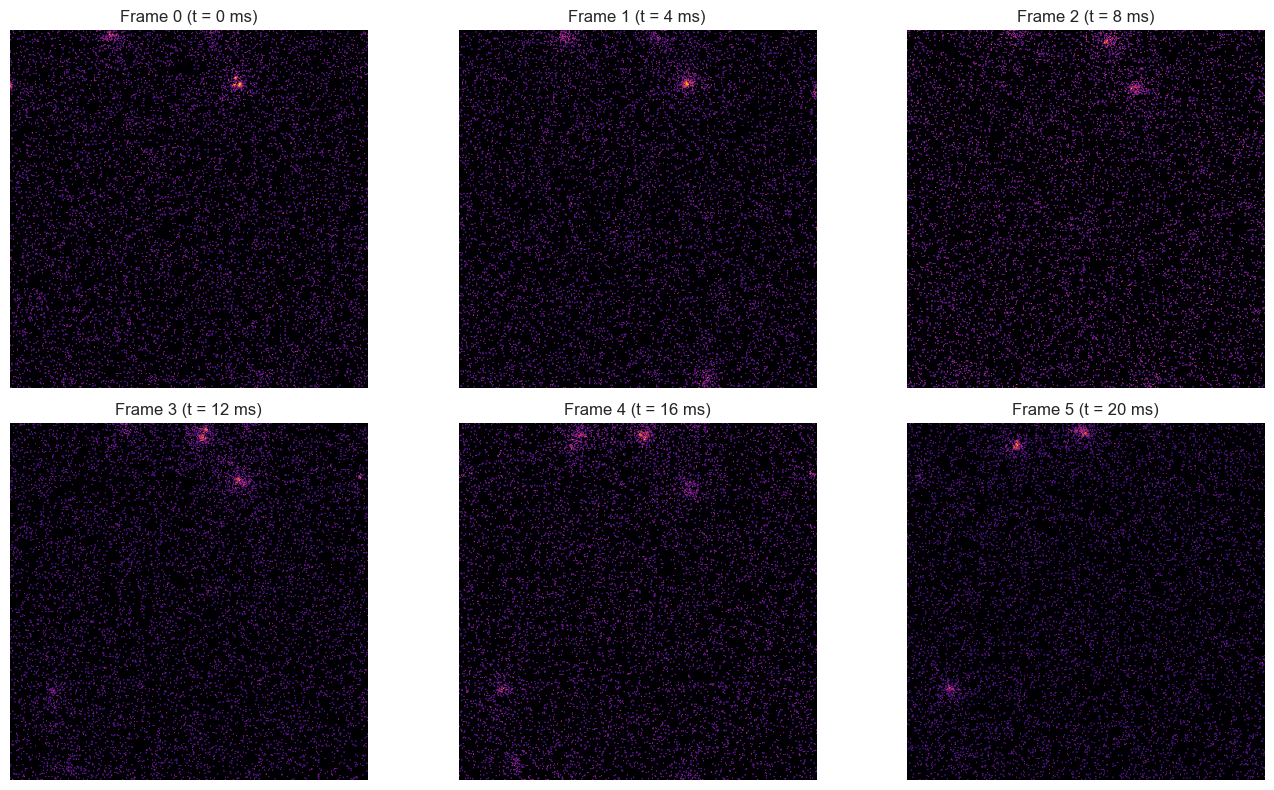

In [11]:
gamma = 0.5

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(frames[i], cmap='inferno', norm=PowerNorm(gamma=gamma))
    ax.set_title(f'Frame {i} (t = {i*frame_time*1e3:.0f} ms)')
    ax.set_axis_off()
plt.tight_layout();

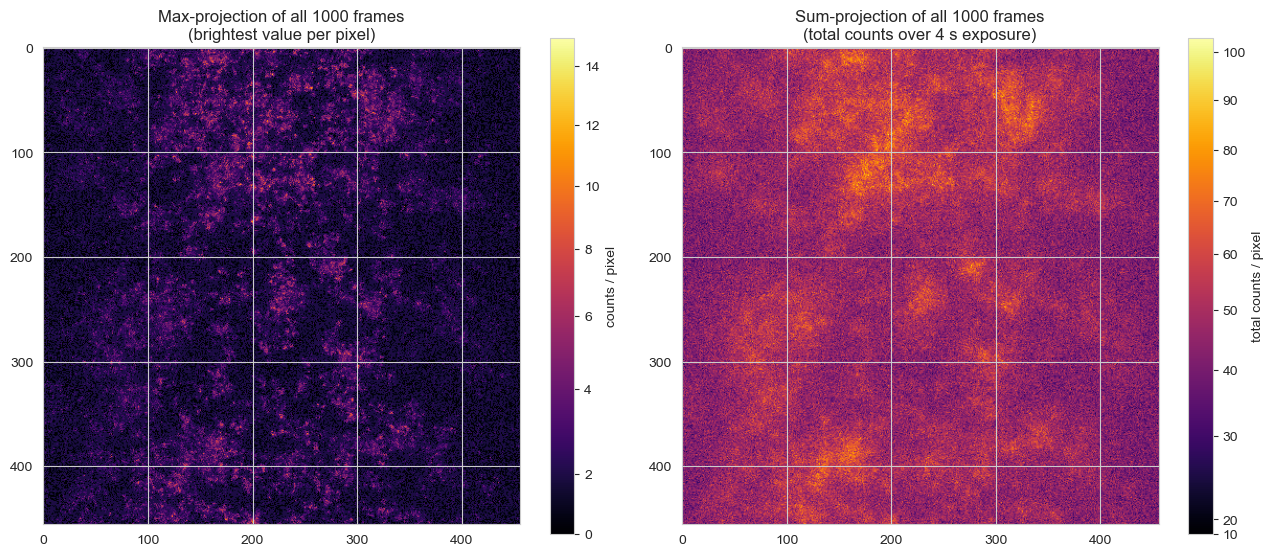

In [12]:
# Projection of ALL 50 ms frames into one image ---
# Max-projection: the brightest value each pixel ever reached (best SNR per
# pixel, shows every molecule that was ever visible).
# Sum-projection: total counts (a 200 s exposure).
frame_max = frames.max(axis=0)
frame_sum = frames.sum(axis=0)

gamma = 0.8

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
im0 = axes[0].imshow(frame_max, cmap='inferno', norm=PowerNorm(gamma=gamma))
axes[0].set_title(f'Max-projection of all {frames.shape[0]} frames\n'
                  '(brightest value per pixel)')
fig.colorbar(im0, ax=axes[0], shrink=0.8, label='counts / pixel')

im1 = axes[1].imshow(frame_sum, cmap='inferno', norm=PowerNorm(gamma=gamma))
axes[1].set_title(f'Sum-projection of all {frames.shape[0]} frames\n'
                  f'(total counts over {t_max:.0f} s exposure)')
fig.colorbar(im1, ax=axes[1], shrink=0.8, label='total counts / pixel')
plt.tight_layout();

<function matplotlib.pyplot.show(close=None, block=None)>

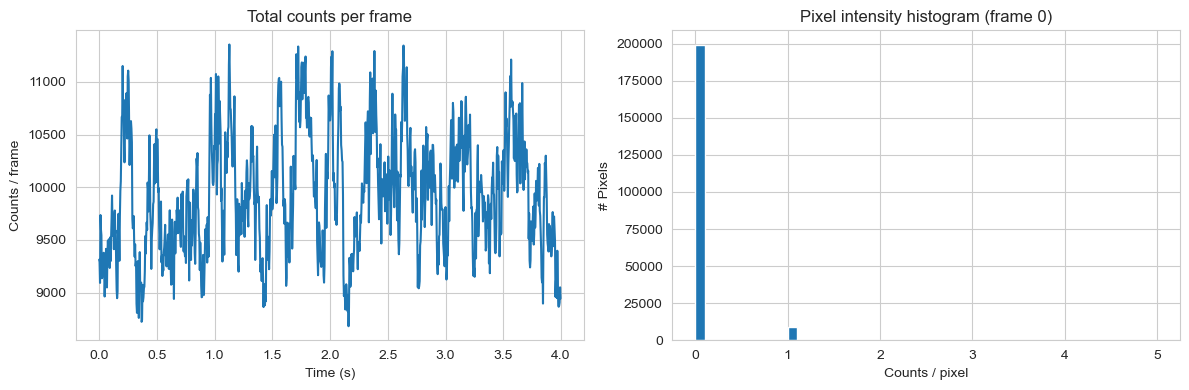

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
t_frames = np.arange(frames.shape[0]) * frame_time
axes[0].plot(t_frames, frames.sum(axis=(1, 2)))
axes[0].set_xlabel('Time (s)'); axes[0].set_ylabel('Counts / frame')
axes[0].set_title('Total counts per frame')

f_max = frames[0].max()
axes[1].hist(frames[0].ravel(), bins=50, range=(0, f_max))
axes[1].set_xlabel('Counts / pixel'); axes[1].set_ylabel('# Pixels')
axes[1].set_title('Pixel intensity histogram (frame 0)')
plt.tight_layout()
plt.show

## 4. Save the camera frames

The frame stack is saved as HDF5 with the acquisition parameters as attributes. The pybromo trajectory file already contains the light-sheet PSF (via `LightSheetPSF.to_hdf5`), so the simulation is fully traceable.


In [14]:
sim_name = S.compact_name()
S.store.close()

filename = os.path.join(OUTPUT_DIR, f'lightsheet_camera_{sim_name}.hdf5')
with tables.open_file(filename, 'w') as f:
    f.create_array('/', 'frames', obj=frames,
                   title='Simulated light-sheet camera frames (uint16)')
    for attr, value in [('frame_time', frame_time),
                        ('t_step', t_step),
                        ('pixel_size_m', pixel_size),
                        ('em_rate', em_rate),
                        ('background_rate', background_rate),
                        ('psf_hash', ls_psf.hash())]:
        f.set_node_attr(f.root, attr, value)
print('Saved:', filename)

Saved: /Users/tomkache/Documents/Arbeit/EAH/Software/python/Lightsheet_smFRET_Simulations/H2MM-FRET-Blinking/ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_mismatch25um/lightsheet_camera_9f33d2_P25_D8e-11_1pM_step1000.0us_t_max4.0s_ID0-0.hdf5


In [15]:
# --- Export the camera frames as a compressed 8-bit .mov (H.264)
# Rescale uint16 photon counts to 0-255 with ONE global factor
# (max of the whole stack -> 255), so intensities stay comparable
# across frames;

intensity_scale = 255.0 / frames.max()
frames_u8 = (frames.astype(np.float64) * intensity_scale).round().clip(0, 255).astype(np.uint8)

# H.264 with the default yuv420p chroma format requires EVEN frame
# dimensions; pad odd ROIs (e.g. 289 -> 290) with black at the right and
# bottom edge. The data occupies [:h, :w]; nothing is cropped or rescaled.
h, w = frames_u8.shape[1], frames_u8.shape[2]
if h % 2 or w % 2:
    padded = np.zeros((frames_u8.shape[0], h + h % 2, w + w % 2), dtype=np.uint8)
    padded[:, :h, :w] = frames_u8
    frames_u8 = padded

video_filename = os.path.join(OUTPUT_DIR, f'lightsheet_camera_{sim_name}.mov')
iio.imwrite(video_filename, frames_u8, fps=int(round(1 / frame_time)),
            codec='libx264', quality=7, macro_block_size=1)
print('Saved:', video_filename,
      f'({frames_u8.shape[1]}x{frames_u8.shape[2]}, data in [:{h}, :{w}])')

Saved: /Users/tomkache/Documents/Arbeit/EAH/Software/python/Lightsheet_smFRET_Simulations/H2MM-FRET-Blinking/ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_mismatch25um/lightsheet_camera_9f33d2_P25_D8e-11_1pM_step1000.0us_t_max4.0s_ID0-0.mov (456x456, data in [:456, :456])
